# Inventory Replenishment Agent
**Course:** AAI 2025 · **Goal:** a daily agent that forecasts demand (EWMA), sizes safety stock from forecast
error and a target service level, projects inventory over *lead time + review period*, and either places a
purchase order (PO) or waits — then is simulated day by day and compared against a static baseline.

**How to run:** run all cells top to bottom (Colab or local Jupyter), or `python inventory_agent.py`.
If `data/sales.csv`, `data/inventory.csv`, `data/params.csv` are missing they are auto-generated (seeded).

## Design Document (1 page)

**Goal.** Each day, for each SKU, decide *how many units to order, or whether to wait*, so that the business keeps shelves stocked (few stockouts, high fill rate) without tying up cash in excess stock. The agent minimises **total cost = holding + stockout + order cost** subject to a per-SKU target **service level**.

**Inputs (per SKU, per day).** Daily sales history through yesterday (`sales.csv`, aggregated per day per SKU) → EWMA demand forecast `f` and running forecast-error `σ`; current on-hand stock and units already on order (`inventory.csv` opening stock + simulation state); policy and cost inputs from `params.csv`: `lead_time_days`, `min_order_qty`, `service_level`, `holding_cost_per_day`, `stockout_cost`, `unit_cost`.

**Outputs.** One decision per SKU per day: **ORDER *q* units** (arrives after the lead time) or **WAIT**, plus a written rationale with the numbers behind it (the daily log).

**Decision rule.** Protection interval `H = lead time + review period`. Safety stock `SS = z(service level) · σ · √H`. Projected inventory `= on-hand + on-order − f·H`. If projected ≥ SS → wait. Otherwise order up to `f·H + SS + cover_days·f`, with at least `min_order_qty`.

**Guardrails & business rules.**
* Respects `min_order_qty` (raises small orders to the MOQ) and accounts for lead time (orders count as on-order until they arrive, so the agent does not double-order).
* Uses the service level to size safety stock, so riskier/more important SKUs hold more buffer.
* Prevents unrealistic over-ordering: the inventory position can never exceed `max_cover_days · f + SS` (and optionally a $ cap); if the cap leaves no room for a legal PO, the agent waits and logs why.
* Holding vs stockout trade-off: waiting saves holding cost but risks lost sales; every order adds holding cost and a fixed PO cost. The service level is the dial between the two.

**Metrics.** *Stockout* = a day on which demand exceeded stock (we also count units short). *Fill rate* = 1 − lost units / demanded units. *Total cost* = holding + stockout + order cost. We also track average and peak inventory value (working capital).

**Ethics & trust.** Stockouts hurt customers and the people who rely on the product (here lost demand, in a real setting possibly essential goods), so the agent is not allowed to "save money" by silently under-stocking: the service-level target and stockout cost make that trade-off explicit. Over-ordering wastes cash and goods and can hide risk, so it is capped. Every decision is written to a **daily log with its rationale** (numbers, rule that fired, guardrail that applied), so a planner can audit, question and override the agent; the agent recommends, a human remains accountable for policy parameters. Forecast error is tracked and reported rather than hidden.

**Assumptions.** Unmet demand is lost (no backorders); SKUs are independent; demand is stationary enough for EWMA (no explicit seasonality model); forecast errors on different days are independent when scaling `σ` by `√H`; data is synthetic.

## 1. Setup & configuration
Every tunable lives in `AgentConfig` (EWMA `alpha`, service level / lead time overrides, cover days, caps, order cost).

In [1]:
import os
import math
import warnings
from dataclasses import dataclass
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

try:                                    # pretty tables in Jupyter, plain print in a terminal
    from IPython.display import display
except ImportError:                     # pragma: no cover
    display = print

DATA_DIR = "data"
OUT_DIR = "outputs"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


@dataclass
class AgentConfig:
    """All knobs for the agent and the simulation (change these, not the code)."""
    alpha: float = 0.1                  # EWMA smoothing for the demand level (higher = reacts faster); 0.1 was chosen on
                                        # tuning seeds 200-229, which are NOT used in the evaluation below
    beta: float = 0.1                   # EWMA smoothing for the squared forecast error (sigma estimate)
    forecaster: str = "ewma"            # "ewma" or "naive" (yesterday = today)
    review_period: int = 1              # days between reviews (the agent reviews daily)
    cover_days: int = 7                 # extra days of demand bought per PO (sets the order cycle)
    max_cover_days: int = 25            # GUARDRAIL: inventory position never exceeds this many days of demand + SS
    max_inventory_value: Optional[float] = None   # GUARDRAIL: optional cap on inventory position value ($) per SKU
    fixed_order_cost: float = 20.0      # cost per PO (assignment allows 0 or a constant)
    warmup_days: int = 14               # history used only to initialise the forecaster / baseline (not simulated)
    service_level_override: Optional[float] = None   # if set, replaces service_level in params.csv for every SKU
    lead_time_override: Optional[int] = None         # if set, replaces lead_time_days in params.csv for every SKU

## 2. Data: generate (if missing), load, aggregate
Three CSVs with the schemas required by the assignment. `make_synthetic` builds 3 SKUs × 120 days with weekly
seasonality, a trend, promo spikes and noise. A few days are split across two sales rows on purpose, so the
aggregation step (sum per day per SKU) does real work.

In [2]:
SKU_PROFILES = {
    #  base = mean units/day, trend = relative change over the horizon, promos = (count, lift)
    "SKU_A": dict(base=40, trend=0.35, promos=(3, 0.9), opening=300,
                  params=dict(unit_cost=12.0, holding_cost_per_day=0.05, stockout_cost=9.0,
                              lead_time_days=5, min_order_qty=60, service_level=0.95)),
    "SKU_B": dict(base=18, trend=0.00, promos=(3, 1.2), opening=150,
                  params=dict(unit_cost=35.0, holding_cost_per_day=0.14, stockout_cost=28.0,
                              lead_time_days=7, min_order_qty=40, service_level=0.97)),
    "SKU_C": dict(base=6, trend=-0.20, promos=(2, 1.5), opening=40,
                  params=dict(unit_cost=8.0, holding_cost_per_day=0.03, stockout_cost=4.0,
                              lead_time_days=3, min_order_qty=20, service_level=0.90)),
}
DOW_FACTOR = np.array([1.00, 0.95, 1.00, 1.05, 1.20, 1.25, 0.80])   # Mon..Sun


def make_synthetic(seed: int = 7, n_days: int = 120, start: str = "2025-01-01"):
    """Return (sales, inventory, params) DataFrames in the assignment's CSV schemas."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range(start, periods=n_days, freq="D")
    rows, inv_rows, par_rows = [], [], []
    for sku, prof in SKU_PROFILES.items():
        t = np.arange(n_days) / (n_days - 1)
        mean = prof["base"] * DOW_FACTOR[dates.dayofweek] * (1 + prof["trend"] * t)
        n_promo, lift = prof["promos"]
        for d in rng.choice(np.arange(20, n_days - 2), size=n_promo, replace=False):
            mean[d:d + 2] *= (1 + lift)                                   # 2-day promo spike
        demand = rng.poisson(mean * rng.lognormal(0, 0.10, n_days))        # noisy integer demand
        for date, q in zip(dates, demand):
            if q >= 2 and rng.random() < 0.10:                             # split some days across 2 sales rows
                a = int(rng.integers(1, q))
                rows += [(date, sku, a), (date, sku, int(q) - a)]
            else:
                rows.append((date, sku, int(q)))
        inv_rows.append((sku, prof["opening"]))
        par_rows.append((sku, *prof["params"].values()))
    sales = pd.DataFrame(rows, columns=["date", "sku", "qty_sold"])
    inventory = pd.DataFrame(inv_rows, columns=["sku", "opening_stock"])
    params = pd.DataFrame(par_rows, columns=["sku", "unit_cost", "holding_cost_per_day", "stockout_cost",
                                             "lead_time_days", "min_order_qty", "service_level"])
    return sales, inventory, params


def write_data(data_dir: str = DATA_DIR, seed: int = 7):
    sales, inventory, params = make_synthetic(seed)
    sales.to_csv(f"{data_dir}/sales.csv", index=False)
    inventory.to_csv(f"{data_dir}/inventory.csv", index=False)
    params.to_csv(f"{data_dir}/params.csv", index=False)


def prepare_data(sales: pd.DataFrame, inventory: pd.DataFrame, params: pd.DataFrame):
    """Validate the inputs and aggregate raw sales rows into daily demand per SKU.

    Returns (daily, opening, params):  daily = DataFrame[date x sku] of units sold,
    opening = Series sku -> opening stock, params = DataFrame indexed by sku.
    """
    needed = {"sales": (sales, {"date", "sku", "qty_sold"}),
              "inventory": (inventory, {"sku", "opening_stock"}),
              "params": (params, {"sku", "unit_cost", "holding_cost_per_day", "stockout_cost",
                                  "lead_time_days", "min_order_qty", "service_level"})}
    for name, (df, cols) in needed.items():
        missing = cols - set(df.columns)
        if missing:
            raise ValueError(f"{name}.csv is missing columns: {sorted(missing)}")
    sales = sales.copy()
    sales["date"] = pd.to_datetime(sales["date"])
    if (sales["qty_sold"] < 0).any():
        raise ValueError("sales.csv contains negative qty_sold")
    skus = sorted(sales["sku"].unique())
    for name, df in (("inventory", inventory), ("params", params)):
        absent = set(skus) - set(df["sku"])
        if absent:
            raise ValueError(f"{name}.csv has no row for SKU(s): {sorted(absent)}")

    # Task 1: aggregate to one number per (day, SKU), then fill the calendar so there are no date gaps.
    daily = sales.groupby(["date", "sku"])["qty_sold"].sum().unstack("sku")[skus]
    full_calendar = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
    gap_days = full_calendar.difference(daily.index)
    if len(gap_days):
        warnings.warn(f"{len(gap_days)} calendar day(s) have no sales rows; treating them as 0 demand.")
    daily = daily.reindex(full_calendar).fillna(0).astype(int)
    daily.index.name = "date"
    return daily, inventory.set_index("sku")["opening_stock"], params.set_index("sku")


def load_data(data_dir: str = DATA_DIR):
    """Read the three CSVs (auto-generating them if absent) and return prepared data."""
    files = [f"{data_dir}/{n}.csv" for n in ("sales", "inventory", "params")]
    if not all(os.path.exists(f) for f in files):
        print("CSV files not found - generating seeded synthetic data.")
        write_data(data_dir)
    return prepare_data(pd.read_csv(files[0]), pd.read_csv(files[1]), pd.read_csv(files[2]))


daily, opening, params = load_data()
print(f"Loaded {len(daily)} days x {daily.shape[1]} SKUs  ({daily.index.min().date()} -> {daily.index.max().date()})")
display(params)
display(opening.to_frame())
display(daily.head())

Loaded 120 days x 3 SKUs  (2025-01-01 -> 2025-04-30)


,unit_cost,holding_cost_per_day,stockout_cost,lead_time_days,min_order_qty,service_level
sku,,,,,,
SKU_A,12.0,0.05,9.0,5,60,0.95
SKU_B,35.0,0.14,28.0,7,40,0.97
SKU_C,8.0,0.03,4.0,3,20,0.90


,opening_stock
sku,
SKU_A,300
SKU_B,150
SKU_C,40


sku,SKU_A,SKU_B,SKU_C
date,,,
2025-01-01,41,20,5
2025-01-02,34,17,11
2025-01-03,37,21,11
2025-01-04,66,17,3
2025-01-05,34,12,4


## 3. Forecaster (EWMA or naive) and forecast error
* **EWMA level:** `f_t+1 = alpha * d_t + (1 - alpha) * f_t` — updated every day after the day's demand is observed.
* **Naive:** `f_t+1 = d_t` (yesterday = today).
* **Forecast error:** `e_t = d_t - f_t` (the forecast that was held *before* seeing day *t*).
  Its squared value is smoothed with its own EWMA (`beta`) to give a running error std-dev `sigma`,
  which feeds the safety-stock formula.

In [3]:
class DemandForecaster:
    """Per-SKU one-step-ahead demand forecaster with a running forecast-error estimate."""

    def __init__(self, history, kind="ewma", alpha=0.3, beta=0.1):
        if kind not in ("ewma", "naive"):
            raise ValueError("kind must be 'ewma' or 'naive'")
        self.kind, self.alpha, self.beta = kind, alpha, beta
        history = np.asarray(history, dtype=float)
        self.level = history[0]
        sq_errors = []
        for d in history[1:]:                       # warm-up: replay history to initialise level and error variance
            sq_errors.append((d - self.level) ** 2)
            self._update_level(d)
        self.var = float(np.mean(sq_errors)) if sq_errors else float(np.var(history))
        self.last_error = 0.0

    def _update_level(self, actual):
        self.level = actual if self.kind == "naive" else self.alpha * actual + (1 - self.alpha) * self.level

    @property
    def forecast(self) -> float:
        """Forecast of average daily demand for the coming days."""
        return max(self.level, 0.0)

    @property
    def sigma(self) -> float:
        """Std-dev of one-day forecast error."""
        return math.sqrt(max(self.var, 1e-9))

    def update(self, actual):
        """Called once per day after demand is observed: update error estimate, then the forecast."""
        self.last_error = actual - self.level
        self.var = (1 - self.beta) * self.var + self.beta * self.last_error ** 2
        self._update_level(actual)

## 4. The agent (decision logic) and the static baseline
**Agent, every day for every SKU** (protection interval `H = lead_time + review_period` days):
1. *Observe* – on-hand after today's receipts, units on order (all arrive within `H`), forecast `f`, error `sigma`.
2. *Safety stock* – `SS = z(service_level) * sigma * sqrt(H)`.
3. *Project* – `projected = on_hand + on_order - f * H`  (inventory just before the next PO could land).
4. *Decide* – if `projected >= SS` → **WAIT** (ordering now only adds holding cost).
   Otherwise → **ORDER**: bring the inventory position up to `f*H + SS + cover_days*f`, but
   * never below `min_order_qty`, and
   * never beyond the cap (`max_cover_days * f + SS`, and optionally `max_inventory_value`) – if the cap leaves no room for a
     legal PO the agent waits and says so.

**Baseline (static `(s, Q)`):** same service level, but mean/std are computed *once* from the warm-up window and never
updated (no forecast). Order a fixed `Q = max(MOQ, cover_days * mean)` whenever inventory position `<= s`.

In [4]:
@dataclass
class SkuParams:
    """Policy and cost inputs for one SKU (after applying any config overrides)."""
    sku: str
    unit_cost: float
    h: float                 # holding cost per unit per day
    p: float                 # stockout cost per unit of lost demand
    L: int                   # lead time (days)
    moq: int                 # minimum order quantity
    service_level: float

    @classmethod
    def from_row(cls, sku, row, cfg: AgentConfig):
        return cls(sku=sku, unit_cost=float(row["unit_cost"]), h=float(row["holding_cost_per_day"]),
                   p=float(row["stockout_cost"]),
                   L=int(cfg.lead_time_override if cfg.lead_time_override is not None else row["lead_time_days"]),
                   moq=int(row["min_order_qty"]),
                   service_level=float(cfg.service_level_override if cfg.service_level_override is not None
                                       else row["service_level"]))


@dataclass
class Decision:
    action: str              # "ORDER" or "WAIT"
    qty: int
    forecast: float
    sigma: float
    safety_stock: float
    projected: float
    rationale: str


class ReplenishmentAgent:
    """Forecast-driven (s, S)-style agent with a dynamic reorder trigger and order-up-to level."""
    name = "EWMA agent"

    def __init__(self, sp: SkuParams, history, cfg: AgentConfig):
        self.sp, self.cfg = sp, cfg
        self.fc = DemandForecaster(history, cfg.forecaster, cfg.alpha, cfg.beta)
        self.z = norm.ppf(sp.service_level)

    def decide(self, on_hand: float, on_order: float) -> Decision:
        sp, cfg = self.sp, self.cfg
        f, sigma = self.fc.forecast, self.fc.sigma
        H = sp.L + cfg.review_period                                  # protection interval (days)
        demand_H = f * H
        safety = self.z * sigma * math.sqrt(H)                        # safety stock from forecast error + service level
        projected = on_hand + on_order - demand_H                     # projected inventory over lead time + review period
        head = (f"fc={f:.1f}/d sigma={sigma:.1f} SS={safety:.1f}; projected inv after {H}d = "
                f"{on_hand:.0f}+{on_order:.0f}-{demand_H:.1f} = {projected:.1f}")

        if projected >= safety:
            return Decision("WAIT", 0, f, sigma, safety, projected,
                            f"{head} >= SS -> enough cover, wait (saves holding cost)")

        position = on_hand + on_order
        target = demand_H + safety + cfg.cover_days * f               # order-up-to level
        cap = cfg.max_cover_days * f + safety                         # guardrail: no unrealistic over-ordering
        if cfg.max_inventory_value is not None:
            cap = min(cap, cfg.max_inventory_value / sp.unit_cost)
        room = cap - position
        if room < sp.moq:
            return Decision("WAIT", 0, f, sigma, safety, projected,
                            f"{head} < SS but cap {cap:.0f} leaves room {room:.0f} < MOQ {sp.moq} -> wait (over-order guardrail)")
        need = target - position
        qty = int(math.ceil(min(max(need, sp.moq), room)))
        notes = []
        if need < sp.moq:
            notes.append(f"raised to MOQ {sp.moq}")
        elif need > room:
            notes.append(f"trimmed to cap {cap:.0f}")
        return Decision("ORDER", qty, f, sigma, safety, projected,
                        f"{head} < SS -> ORDER {qty} (target {target:.0f}, position {position:.0f}"
                        f"{'; ' + ', '.join(notes) if notes else ''}); arrives in {sp.L}d")

    def observe(self, demand: float):
        self.fc.update(demand)                                        # forecast updates daily


class StaticReorderPolicy:
    """Baseline: fixed (s, Q) with s and Q computed once from the warm-up window. No forecasting."""
    name = "Static (s,Q) baseline"

    def __init__(self, sp: SkuParams, history, cfg: AgentConfig):
        self.sp = sp
        history = np.asarray(history, dtype=float)
        mu0, sd0 = history.mean(), history.std(ddof=1)
        H = sp.L + cfg.review_period
        self.s = mu0 * H + norm.ppf(sp.service_level) * sd0 * math.sqrt(H)
        self.Q = int(math.ceil(max(sp.moq, cfg.cover_days * mu0)))
        self.mu0, self.sd0 = mu0, sd0

    def decide(self, on_hand: float, on_order: float) -> Decision:
        position = on_hand + on_order
        if position <= self.s:
            return Decision("ORDER", self.Q, self.mu0, self.sd0, 0.0, position,
                            f"position {position:.0f} <= fixed s={self.s:.0f} -> ORDER fixed Q={self.Q}")
        return Decision("WAIT", 0, self.mu0, self.sd0, 0.0, position,
                        f"position {position:.0f} > fixed s={self.s:.0f} -> wait")

    def observe(self, demand: float):
        pass                                                          # static: never learns


def NaiveForecastAgent(sp, history, cfg):
    """Same agent logic, but with the 'yesterday = today' forecaster."""
    cfg = AgentConfig(**{**cfg.__dict__, "forecaster": "naive"})
    agent = ReplenishmentAgent(sp, history, cfg)
    agent.name = "Naive-forecast agent"
    return agent

## 5. Day-by-day simulation
Order of events each day *t* (per SKU):
1. **Receive** POs whose arrival day is *t* (an order placed on day *d* arrives on day *d + lead_time*).
2. **Decide** – the agent sees only data through day *t-1* and today's stock position; it may place a PO.
3. **Demand** occurs; units are sold from on-hand. Unmet demand is **lost** (no backorders) and costs `stockout_cost` per unit.
4. **Costs** – holding cost on end-of-day stock, stockout cost on lost units, fixed cost per PO.
5. **Learn** – the actual demand updates the forecaster.

The first `warmup_days` only initialise the forecaster; the simulation runs on the remaining days.
SKUs are independent (no shared budget), so each is simulated on its own and the results are merged.

In [5]:
def simulate(daily, opening, params, cfg: AgentConfig, policy_cls=ReplenishmentAgent) -> pd.DataFrame:
    """Simulate one policy over all SKUs; return the daily log (one row per date x SKU)."""
    records = []
    n = len(daily)
    for sku in daily.columns:
        sp = SkuParams.from_row(sku, params.loc[sku], cfg)
        demand = daily[sku].to_numpy()
        policy = policy_cls(sp, demand[:cfg.warmup_days], cfg)
        on_hand = float(opening[sku])
        pipeline = []                                                 # list of (arrival_day_index, qty)
        for t in range(cfg.warmup_days, n):
            arrivals = sum(q for a, q in pipeline if a == t)          # 1. receive
            pipeline = [(a, q) for a, q in pipeline if a > t]
            on_hand += arrivals
            on_order = sum(q for _, q in pipeline)

            dec = policy.decide(on_hand, on_order)                    # 2. decide
            order_cost = 0.0
            if dec.qty > 0:
                pipeline.append((t + sp.L, dec.qty))
                order_cost = cfg.fixed_order_cost

            d = int(demand[t])                                        # 3. demand
            sold = min(on_hand, d)
            lost = d - sold
            on_hand_start, on_hand = on_hand, on_hand - sold

            records.append(dict(                                      # 4. costs + log
                date=daily.index[t], sku=sku, forecast=dec.forecast, sigma=dec.sigma,
                safety_stock=dec.safety_stock, on_hand_start=on_hand_start, on_order=on_order,
                projected=dec.projected, action=dec.action, order_qty=dec.qty, arrivals=arrivals,
                demand=d, sold=sold, lost=lost, on_hand_end=on_hand, unit_cost=sp.unit_cost,
                holding_cost=sp.h * on_hand, stockout_cost=sp.p * lost, order_cost=order_cost,
                rationale=dec.rationale))
            policy.observe(d)                                         # 5. learn
    return pd.DataFrame(records).sort_values(["date", "sku"]).reset_index(drop=True)


def print_daily_log(log: pd.DataFrame, max_rows: Optional[int] = None):
    """Print the agent's day-by-day decisions with their rationale (transparency)."""
    rows = log if max_rows is None else log.head(max_rows)
    for r in rows.itertuples():
        print(f"{r.date:%Y-%m-%d} {r.sku} | oh={r.on_hand_start:5.0f} (+{r.arrivals:3.0f} in) "
              f"| dem={r.demand:3.0f} lost={r.lost:3.0f} | {r.action:5s} {r.order_qty:4.0f} | {r.rationale}")

## 6. Metrics
* **Stockout** – a day where demand exceeded stock (`stockout_days`) and the units lost (`units_short`).
* **Fill rate** – `1 - lost units / demanded units` (share of demand served from stock).
* **Total cost** – `holding + stockout + order` cost. Purchase cost is not included (every policy buys what it sells);
  `unit_cost` is used for the *inventory value* (working capital) metrics instead.

In [6]:
def compute_kpis(log: pd.DataFrame) -> pd.DataFrame:
    """KPIs per SKU plus a TOTAL row, computed from the daily log."""
    g = log.assign(inv_value=log["on_hand_end"] * log["unit_cost"]).groupby("sku")
    k = pd.DataFrame({
        "demand": g["demand"].sum(), "units_short": g["lost"].sum(),
        "stockout_days": g["lost"].apply(lambda s: int((s > 0).sum())),
        "orders": g["order_qty"].apply(lambda s: int((s > 0).sum())),
        "holding_cost": g["holding_cost"].sum(), "stockout_cost": g["stockout_cost"].sum(),
        "order_cost": g["order_cost"].sum(),
        "avg_inv_value": g["inv_value"].mean(), "peak_inv_value": g["inv_value"].max()})
    total = k.sum()
    total["peak_inv_value"] = log.assign(v=log["on_hand_end"] * log["unit_cost"]).groupby("date")["v"].sum().max()
    k.loc["TOTAL"] = total
    k["fill_rate"] = 1 - k["units_short"] / k["demand"]
    k["total_cost"] = k["holding_cost"] + k["stockout_cost"] + k["order_cost"]
    return k[["demand", "units_short", "fill_rate", "stockout_days", "orders", "holding_cost", "stockout_cost",
              "order_cost", "total_cost", "avg_inv_value", "peak_inv_value"]]


def run_policies(daily, opening, params, cfg):
    """Simulate baseline, naive-forecast agent and EWMA agent; return {name: (log, kpis)}."""
    out = {}
    for cls in (StaticReorderPolicy, NaiveForecastAgent, ReplenishmentAgent):
        log = simulate(daily, opening, params, cfg, cls)
        out[cls.name] = (log, compute_kpis(log))
    return out


# NaiveForecastAgent is a factory function; give it a name so run_policies can label it.
NaiveForecastAgent.name = "Naive-forecast agent"

cfg = AgentConfig()                                   # defaults: alpha=0.1, cover_days=7, order cost=$20/PO
results = run_policies(daily, opening, params, cfg)
BASE, NAIVE, AGENT = "Static (s,Q) baseline", "Naive-forecast agent", "EWMA agent"

## 7. Daily agent log (EWMA agent)
One line per day per SKU: stock, demand, action, and the numbers behind the decision. The full log is also saved to
`outputs/agent_daily_log.csv`.

In [7]:
agent_log = results[AGENT][0]
agent_log.to_csv(f"{OUT_DIR}/agent_daily_log.csv", index=False)
print_daily_log(agent_log)

2025-01-15 SKU_A | oh=  300 (+  0 in) | dem= 37 lost=  0 | WAIT     0 | fc=40.9/d sigma=9.7 SS=39.1; projected inv after 6d = 300+0-245.5 = 54.5 >= SS -> enough cover, wait (saves holding cost)
2025-01-15 SKU_B | oh=  150 (+  0 in) | dem= 20 lost=  0 | ORDER  119 | fc=16.1/d sigma=5.0 SS=26.4; projected inv after 8d = 150+0-129.1 = 20.9 < SS -> ORDER 119 (target 268, position 150); arrives in 7d
2025-01-15 SKU_C | oh=   40 (+  0 in) | dem=  9 lost=  0 | WAIT     0 | fc=6.3/d sigma=3.7 SS=9.5; projected inv after 4d = 40+0-25.4 = 14.6 >= SS -> enough cover, wait (saves holding cost)
2025-01-16 SKU_A | oh=  263 (+  0 in) | dem= 30 lost=  0 | ORDER  302 | fc=40.5/d sigma=9.3 SS=37.4; projected inv after 6d = 263+0-243.1 = 19.9 < SS -> ORDER 302 (target 564, position 263); arrives in 5d
2025-01-16 SKU_B | oh=  130 (+  0 in) | dem= 17 lost=  0 | WAIT     0 | fc=16.5/d sigma=4.9 SS=25.9; projected inv after 8d = 130+119-132.2 = 116.8 >= SS -> enough cover, wait (saves holding cost)
2025-01-1

## 8. Results: agent vs baseline

,demand,units_short,fill_rate,stockout_days,orders,holding_cost,stockout_cost,order_cost,total_cost,avg_inv_value,peak_inv_value
"Static (s,Q) baseline",8185.0,558.0,0.932,21.0,50.0,1690.05,6808.0,1000.0,9498.05,3932.387,7954.0
Naive-forecast agent,8185.0,41.0,0.995,4.0,25.0,6248.93,1148.0,500.0,7896.93,14584.981,37019.0
EWMA agent,8185.0,39.0,0.995,2.0,43.0,2852.49,346.0,860.0,4058.49,6630.774,15202.0



--- Static (s,Q) baseline: per SKU ---


,demand,units_short,fill_rate,stockout_days,orders,holding_cost,stockout_cost,order_cost,total_cost,avg_inv_value,peak_inv_value
sku,,,,,,,,,,,
SKU_A,5452.0,464.0,0.915,13.0,17.0,740.85,4176.0,340.0,5256.85,1677.396,3828.0
SKU_B,2102.0,94.0,0.955,8.0,19.0,845.46,2632.0,380.0,3857.46,1994.009,5075.0
SKU_C,631.0,0.0,1.000,0.0,14.0,103.74,0.0,280.0,383.74,260.981,464.0
TOTAL,8185.0,558.0,0.932,21.0,50.0,1690.05,6808.0,1000.0,9498.05,3932.387,7954.0



--- Naive-forecast agent: per SKU ---


,demand,units_short,fill_rate,stockout_days,orders,holding_cost,stockout_cost,order_cost,total_cost,avg_inv_value,peak_inv_value
sku,,,,,,,,,,,
SKU_A,5452.0,0.0,1.000,0.0,12.0,2037.05,0.0,240.0,2277.05,4612.189,14340.0
SKU_B,2102.0,41.0,0.980,4.0,6.0,3963.12,1148.0,120.0,5231.12,9346.981,28455.0
SKU_C,631.0,0.0,1.000,0.0,7.0,248.76,0.0,140.0,388.76,625.811,1728.0
TOTAL,8185.0,41.0,0.995,4.0,25.0,6248.93,1148.0,500.0,7896.93,14584.981,37019.0



--- EWMA agent: per SKU ---


,demand,units_short,fill_rate,stockout_days,orders,holding_cost,stockout_cost,order_cost,total_cost,avg_inv_value,peak_inv_value
sku,,,,,,,,,,,
SKU_A,5452.0,38.0,0.993,1.0,15.0,1195.10,342.0,300.0,1837.10,2705.887,7488.0
SKU_B,2102.0,0.0,1.000,0.0,14.0,1555.96,0.0,280.0,1835.96,3669.717,8435.0
SKU_C,631.0,1.0,0.998,1.0,14.0,101.43,4.0,280.0,385.43,255.170,496.0
TOTAL,8185.0,39.0,0.995,2.0,43.0,2852.49,346.0,860.0,4058.49,6630.774,15202.0



EWMA agent vs static baseline:  total cost 4,058 vs 9,498 (-57.3%),  fill rate 99.5% vs 93.2% (+6.3 pts),  units short 39 vs 558,  avg inventory value $6,631 vs $3,932


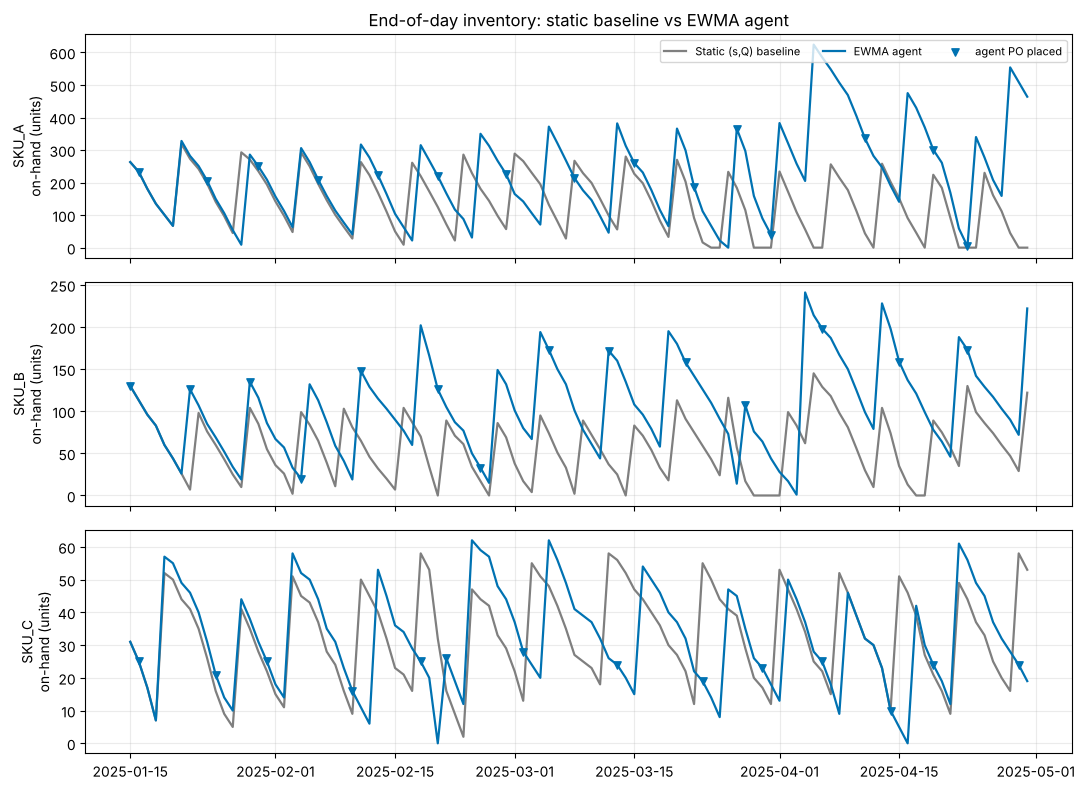

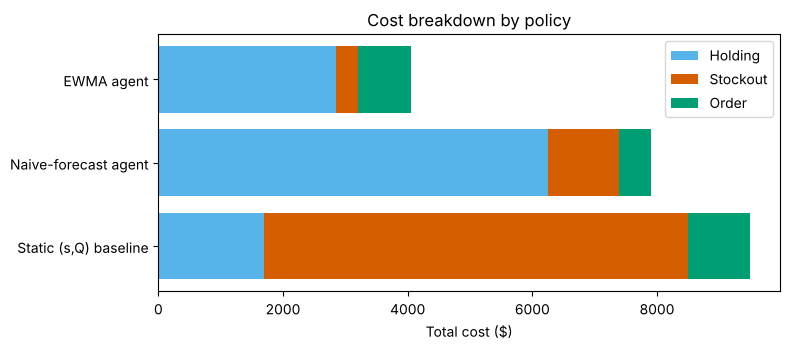

In [8]:
summary = pd.DataFrame({name: kp.loc["TOTAL"] for name, (_, kp) in results.items()}).T
display(summary.round(3))
for name, (_, kp) in results.items():
    print(f"\n--- {name}: per SKU ---")
    display(kp.round(3))

b, a = summary.loc[BASE], summary.loc[AGENT]
print(f"\nEWMA agent vs static baseline:  total cost {a.total_cost:,.0f} vs {b.total_cost:,.0f} "
      f"({(a.total_cost / b.total_cost - 1):+.1%}),  fill rate {a.fill_rate:.1%} vs {b.fill_rate:.1%} "
      f"({(a.fill_rate - b.fill_rate) * 100:+.1f} pts),  units short {a.units_short:.0f} vs {b.units_short:.0f},  "
      f"avg inventory value ${a.avg_inv_value:,.0f} vs ${b.avg_inv_value:,.0f}")

# Charts -------------------------------------------------------------------------------------------------
COLORS = {BASE: "#7f7f7f", NAIVE: "#e69f00", AGENT: "#0072b2"}          # colour-blind-safe palette
fig, axes = plt.subplots(len(daily.columns), 1, figsize=(11, 8), sharex=True)
for ax, sku in zip(np.atleast_1d(axes), daily.columns):
    for name in (BASE, AGENT):
        lg = results[name][0].query("sku == @sku")
        ax.plot(lg["date"], lg["on_hand_end"], label=name, color=COLORS[name], lw=1.6)
    po = results[AGENT][0].query("sku == @sku and order_qty > 0")
    ax.scatter(po["date"], po["on_hand_end"], marker="v", color=COLORS[AGENT], s=28, zorder=3, label="agent PO placed")
    ax.set_ylabel(f"{sku}\non-hand (units)")
    ax.grid(alpha=0.25)
np.atleast_1d(axes)[0].legend(ncol=3, loc="upper right", fontsize=8)
np.atleast_1d(axes)[0].set_title("End-of-day inventory: static baseline vs EWMA agent")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/inventory_trajectories.png", dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
bottom = np.zeros(len(results))
for col, label, color in (("holding_cost", "Holding", "#56b4e9"), ("stockout_cost", "Stockout", "#d55e00"),
                          ("order_cost", "Order", "#009e73")):
    vals = summary[col].to_numpy(dtype=float)
    ax.barh(summary.index, vals, left=bottom, label=label, color=color)
    bottom += vals
ax.set_xlabel("Total cost ($)"); ax.legend(); ax.set_title("Cost breakdown by policy")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cost_breakdown.png", dpi=130); plt.show()

## 9. Robustness and a fairness check
Two honest questions about the headline result:
1. **Is it just luck of one dataset?** Re-generate demand with 30 other seeds (100-129; the default `alpha` was chosen on
   different seeds, 200-229) and compare the policies on average.
2. **Is the baseline just under-stocked?** The static baseline is built from the same service level, but from a static
   14-day estimate, so it can miss its own target when demand trends or spikes. We therefore also give the baseline a
   *hand-tuned, much higher* service level (0.999) - what an analyst would do after seeing it stock out.

In [9]:
BASE_TUNED = "Static (s,Q), hand-tuned to SL=0.999"


def run_tuned_baseline(d, o, p, cfg, service_level=0.999):
    c = AgentConfig(**{**cfg.__dict__, "service_level_override": service_level})
    return compute_kpis(simulate(d, o, p, c, StaticReorderPolicy))


def multi_seed(seeds, cfg):
    rows = []
    for s in seeds:
        d, o, p = prepare_data(*make_synthetic(seed=s))
        kpis = {name: kp for name, (_, kp) in run_policies(d, o, p, cfg).items()}
        kpis[BASE_TUNED] = run_tuned_baseline(d, o, p, cfg)
        for name, kp in kpis.items():
            t = kp.loc["TOTAL"]
            rows.append(dict(seed=s, policy=name, total_cost=t.total_cost, fill_rate=t.fill_rate,
                             units_short=t.units_short, avg_inv_value=t.avg_inv_value))
    return pd.DataFrame(rows)


ms = multi_seed(range(100, 130), cfg)
ms_summary = ms.groupby("policy")[["total_cost", "fill_rate", "units_short", "avg_inv_value"]].agg(["mean", "std"]).round(3)
display(ms_summary)
piv = ms.pivot(index="seed", columns="policy", values="total_cost")
for ref in (BASE, BASE_TUNED):
    print(f"EWMA agent vs {ref:40s}: lower cost in {(piv[AGENT] < piv[ref]).mean():4.0%} of 30 seeds, "
          f"mean cost change {(piv[AGENT].mean() / piv[ref].mean() - 1):+.1%}")

total_cost           fill_rate        units_short          avg_inv_value          
                                           mean       std      mean    std        mean      std          mean       std
policy                                                                                                                 
EWMA agent                             5781.625   892.486     0.986  0.007     116.233   56.039      7286.219   262.669
Naive-forecast agent                   7714.360  1254.157     0.995  0.006      44.100   52.322     15082.049  2026.034
Static (s,Q) baseline                  8238.891  2024.860     0.947  0.023     440.500  193.291      4909.621   592.225
Static (s,Q), hand-tuned to SL=0.999   5563.845   998.081     0.980  0.011     164.500   90.099      5844.963   766.295

EWMA agent vs Static (s,Q) baseline                   : lower cost in  90% of 30 seeds, mean cost change -29.8%
EWMA agent vs Static (s,Q), hand-tuned to SL=0.999    : lower cost in  27% of 30 seeds, mean cost change +3.9%


## 10. Sensitivity: the inventory-vs-service trade-off
Sweep the target service level for **both** the agent and the static baseline (and the EWMA `alpha`) to see how much
extra inventory each point of fill rate costs, and whether the agent sits on a better frontier than the baseline.

EWMA agent - target service level sweep

,service_level,fill_rate,units_short,holding_cost,stockout_cost,total_cost,avg_inv_value
0,0.800,0.985,126.0,2428.60,1704.0,4972.60,5645.689
1,0.900,0.989,92.0,2612.69,1260.0,4732.69,6073.632
2,0.950,0.995,40.0,2796.39,398.0,4054.39,6499.415
3,0.970,0.996,31.0,2896.02,279.0,4035.02,6732.057
4,0.990,0.998,17.0,3102.75,153.0,4115.75,7214.075
5,0.999,1.000,0.0,3440.57,0.0,4300.57,8000.991


Static baseline - target service level sweep


,service_level,fill_rate,units_short,holding_cost,stockout_cost,total_cost,avg_inv_value
0,0.800,0.919,664.0,1539.54,9434.0,11953.54,3583.425
1,0.900,0.924,626.0,1561.26,8370.0,10911.26,3631.726
2,0.950,0.926,608.0,1617.69,8208.0,10805.69,3763.028
3,0.970,0.957,352.0,1795.88,4954.0,7769.88,4174.085
4,0.990,0.960,330.0,1859.70,4338.0,7217.70,4324.009
5,0.999,0.968,261.0,1978.48,3717.0,6715.48,4603.132


EWMA agent - alpha sweep (this dataset; one run, so noisy)


,alpha,fill_rate,total_cost,avg_inv_value
0,0.05,0.989,4424.95,6319.774
1,0.10,0.995,4058.49,6630.774
2,0.20,0.990,5440.96,7377.632
3,0.30,0.990,5191.06,7543.217
4,0.50,0.988,6641.55,9558.575
5,0.80,0.991,7363.78,12090.462


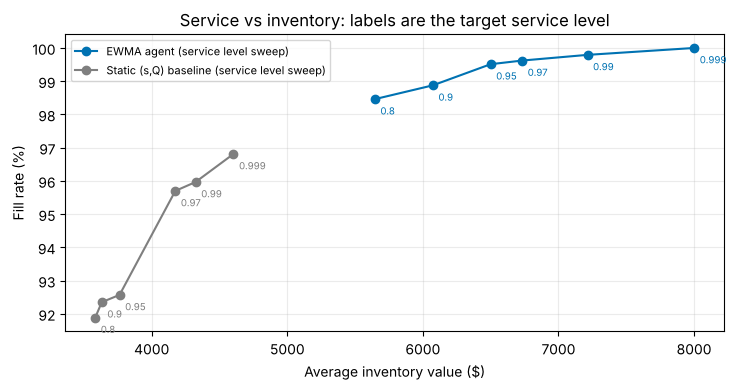

In [10]:
def service_sweep(policy_cls, levels=(0.80, 0.90, 0.95, 0.97, 0.99, 0.999)):
    rows = []
    for sl in levels:
        kp = compute_kpis(simulate(daily, opening, params, AgentConfig(service_level_override=sl), policy_cls)).loc["TOTAL"]
        rows.append(dict(service_level=sl, fill_rate=kp.fill_rate, units_short=kp.units_short,
                         holding_cost=kp.holding_cost, stockout_cost=kp.stockout_cost,
                         total_cost=kp.total_cost, avg_inv_value=kp.avg_inv_value))
    return pd.DataFrame(rows)


sweep = service_sweep(ReplenishmentAgent)
sweep_base = service_sweep(StaticReorderPolicy)
print("EWMA agent - target service level sweep"); display(sweep.round(3))
print("Static baseline - target service level sweep"); display(sweep_base.round(3))

alpha_sweep = []
for al in (0.05, 0.1, 0.2, 0.3, 0.5, 0.8):
    kp = compute_kpis(simulate(daily, opening, params, AgentConfig(alpha=al))).loc["TOTAL"]
    alpha_sweep.append(dict(alpha=al, fill_rate=kp.fill_rate, total_cost=kp.total_cost, avg_inv_value=kp.avg_inv_value))
print("EWMA agent - alpha sweep (this dataset; one run, so noisy)"); display(pd.DataFrame(alpha_sweep).round(3))

fig, ax = plt.subplots(figsize=(7.5, 4))
for df_, name in ((sweep, AGENT), (sweep_base, BASE)):
    ax.plot(df_["avg_inv_value"], df_["fill_rate"] * 100, "o-", color=COLORS[name], label=f"{name} (service level sweep)")
    for r in df_.itertuples():
        ax.annotate(f"{r.service_level:g}", (r.avg_inv_value, r.fill_rate * 100), textcoords="offset points",
                    xytext=(4, -11), fontsize=7, color=COLORS[name])
ax.set_xlabel("Average inventory value ($)"); ax.set_ylabel("Fill rate (%)"); ax.grid(alpha=0.25); ax.legend(fontsize=8)
ax.set_title("Service vs inventory: labels are the target service level")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/tradeoff_curve.png", dpi=130); plt.show()

## 11. Trade-off reflection & what the results do (and don't) show

**Headline (main dataset, default settings).** Against the static `(s, Q)` baseline the EWMA agent cut total cost from **$9,498 to $4,058 (−57%)**, raised fill rate from **93.2% to 99.5%**, and reduced stockout days from 21 to 2 (558 → 39 units short). It did this by holding **more** stock (average inventory value $6.6k vs $3.9k): stockout cost per unit is roughly 130–200× the daily holding cost per unit, so buying service with inventory is cheap here.

**How much to trust that number.**
* Over 30 other random datasets the saving against the same baseline is **smaller but consistent: −29.8% on average, with lower cost in 90% of seeds** (fill 98.6% vs 94.7%).
* The baseline is deliberately simple: its `s` comes from a static 14-day window, so it under-delivers on its own service target when demand trends or spikes (its fill rate stays below 97% even if its service level is pushed to 0.999). When we give it a **hand-tuned service level of 0.999** (the highest of the levels 0.90–0.999 tried on separate seeds) it **matches the agent**: it is about 4% cheaper on average and wins in 73% of seeds, with a similar fill rate (98.0% vs 98.6%). So the honest claim is: *the agent reaches high service automatically and adapts to demand shifts without anyone re-tuning it*, not that forecasting beats every well-tuned fixed rule on this synthetic data.
* "Yesterday = today" is a poor forecast here: it chases promo spikes, buys far more stock (avg inventory $14.6k, peak $37k) and costs $7.9k — a smoothed forecast (EWMA) gives almost the same fill rate at less than half the inventory.

**Inventory vs service.** The sweep shows diminishing returns: lifting the agent's target service level from 0.80 to 0.95 raises fill rate from 98.5% to 99.5% for about $850 of extra average inventory, and going from 0.95 to 0.999 buys the last ~0.5 points for another ~$1.5k of inventory. Total cost is flat-to-rising beyond a service level of about 0.95–0.97, which is where the holding cost of extra safety stock starts to outweigh the stockout cost it prevents. Realised fill rate (units) is higher than the target *cycle* service level (probability of no stockout in a cycle) because stockouts are usually small and because the error estimate also contains weekly seasonality, which makes the safety stock somewhat conservative.

**Limitations.** Synthetic data; single echelon; no backorders; SKUs independent; EWMA ignores day-of-week seasonality (it lands in `σ` instead); orders still in transit at the end of the horizon are not penalised for either policy; `alpha = 0.1` was picked on separate tuning seeds and the one-run alpha sweep above is noisy.

## Scaling Note (≤ ½ page)

**Cloud deployment.** Package the agent as a container (Docker) and run it as a scheduled job (e.g., a nightly Cloud Run job / AWS ECS task triggered by EventBridge or Cloud Scheduler) after the day's sales close. It reads sales, stock and parameters from a warehouse or object store (BigQuery/S3), writes recommended POs and the decision log back, and sends POs to a human approval queue before they go to suppliers. Per-SKU logic is independent, so it parallelises across SKUs (one task per batch of SKUs).

**Monitoring.** Alert if rolling fill rate drops below target (e.g., 7-day fill rate < service level − 3 pts), if forecast error (WAPE/bias) drifts above its baseline, if stockout days spike, or if the job misses its schedule. Dashboards show fill rate, forecast error, stockouts, orders placed and the daily decision log per SKU.

**Reliability.** Retry reads/writes with exponential backoff; make the job idempotent (one run per SKU-date, keyed so reruns do not duplicate POs). Validate inputs (schema, negative quantities, missing days, unknown SKUs); on missing data fall back to the last good forecast and flag it, and on repeated failure freeze orders and page a human rather than guess.

**Cost controls.** Per-SKU and portfolio inventory caps (days of cover and $ value), a maximum PO size and daily PO budget requiring approval above a threshold, and working-capital tracking (average and peak inventory value) reported next to fill rate.